[*] Đang thực hiện EDA trên tập Train: 32,940 mẫu.


C:\Users\ACER NITRO 5\AppData\Local\Temp\ipykernel_5020\2276032103.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='y', data=train_df, palette=['#4A90E2', '#E74C3C'])


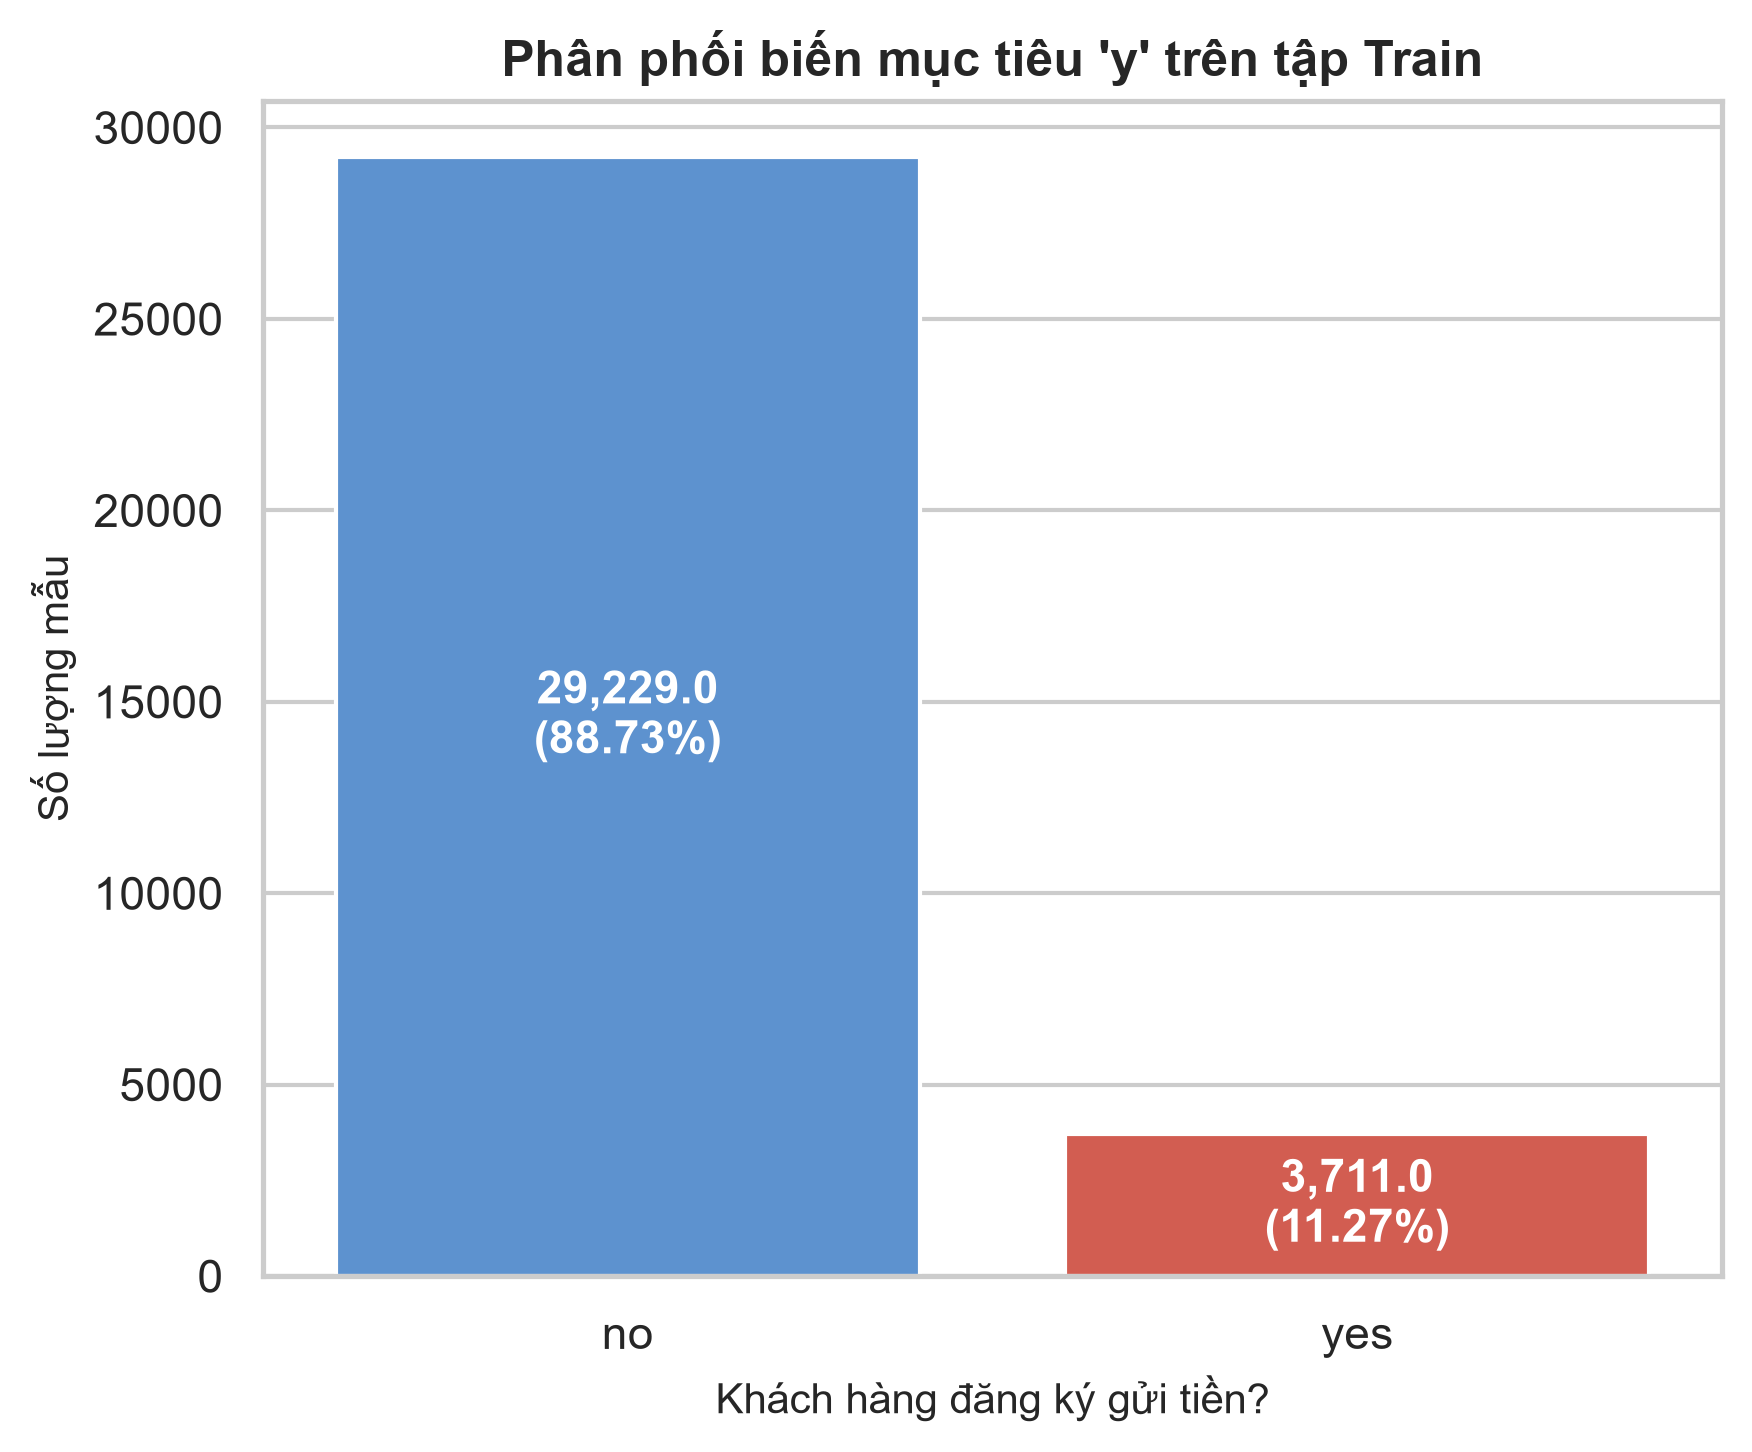

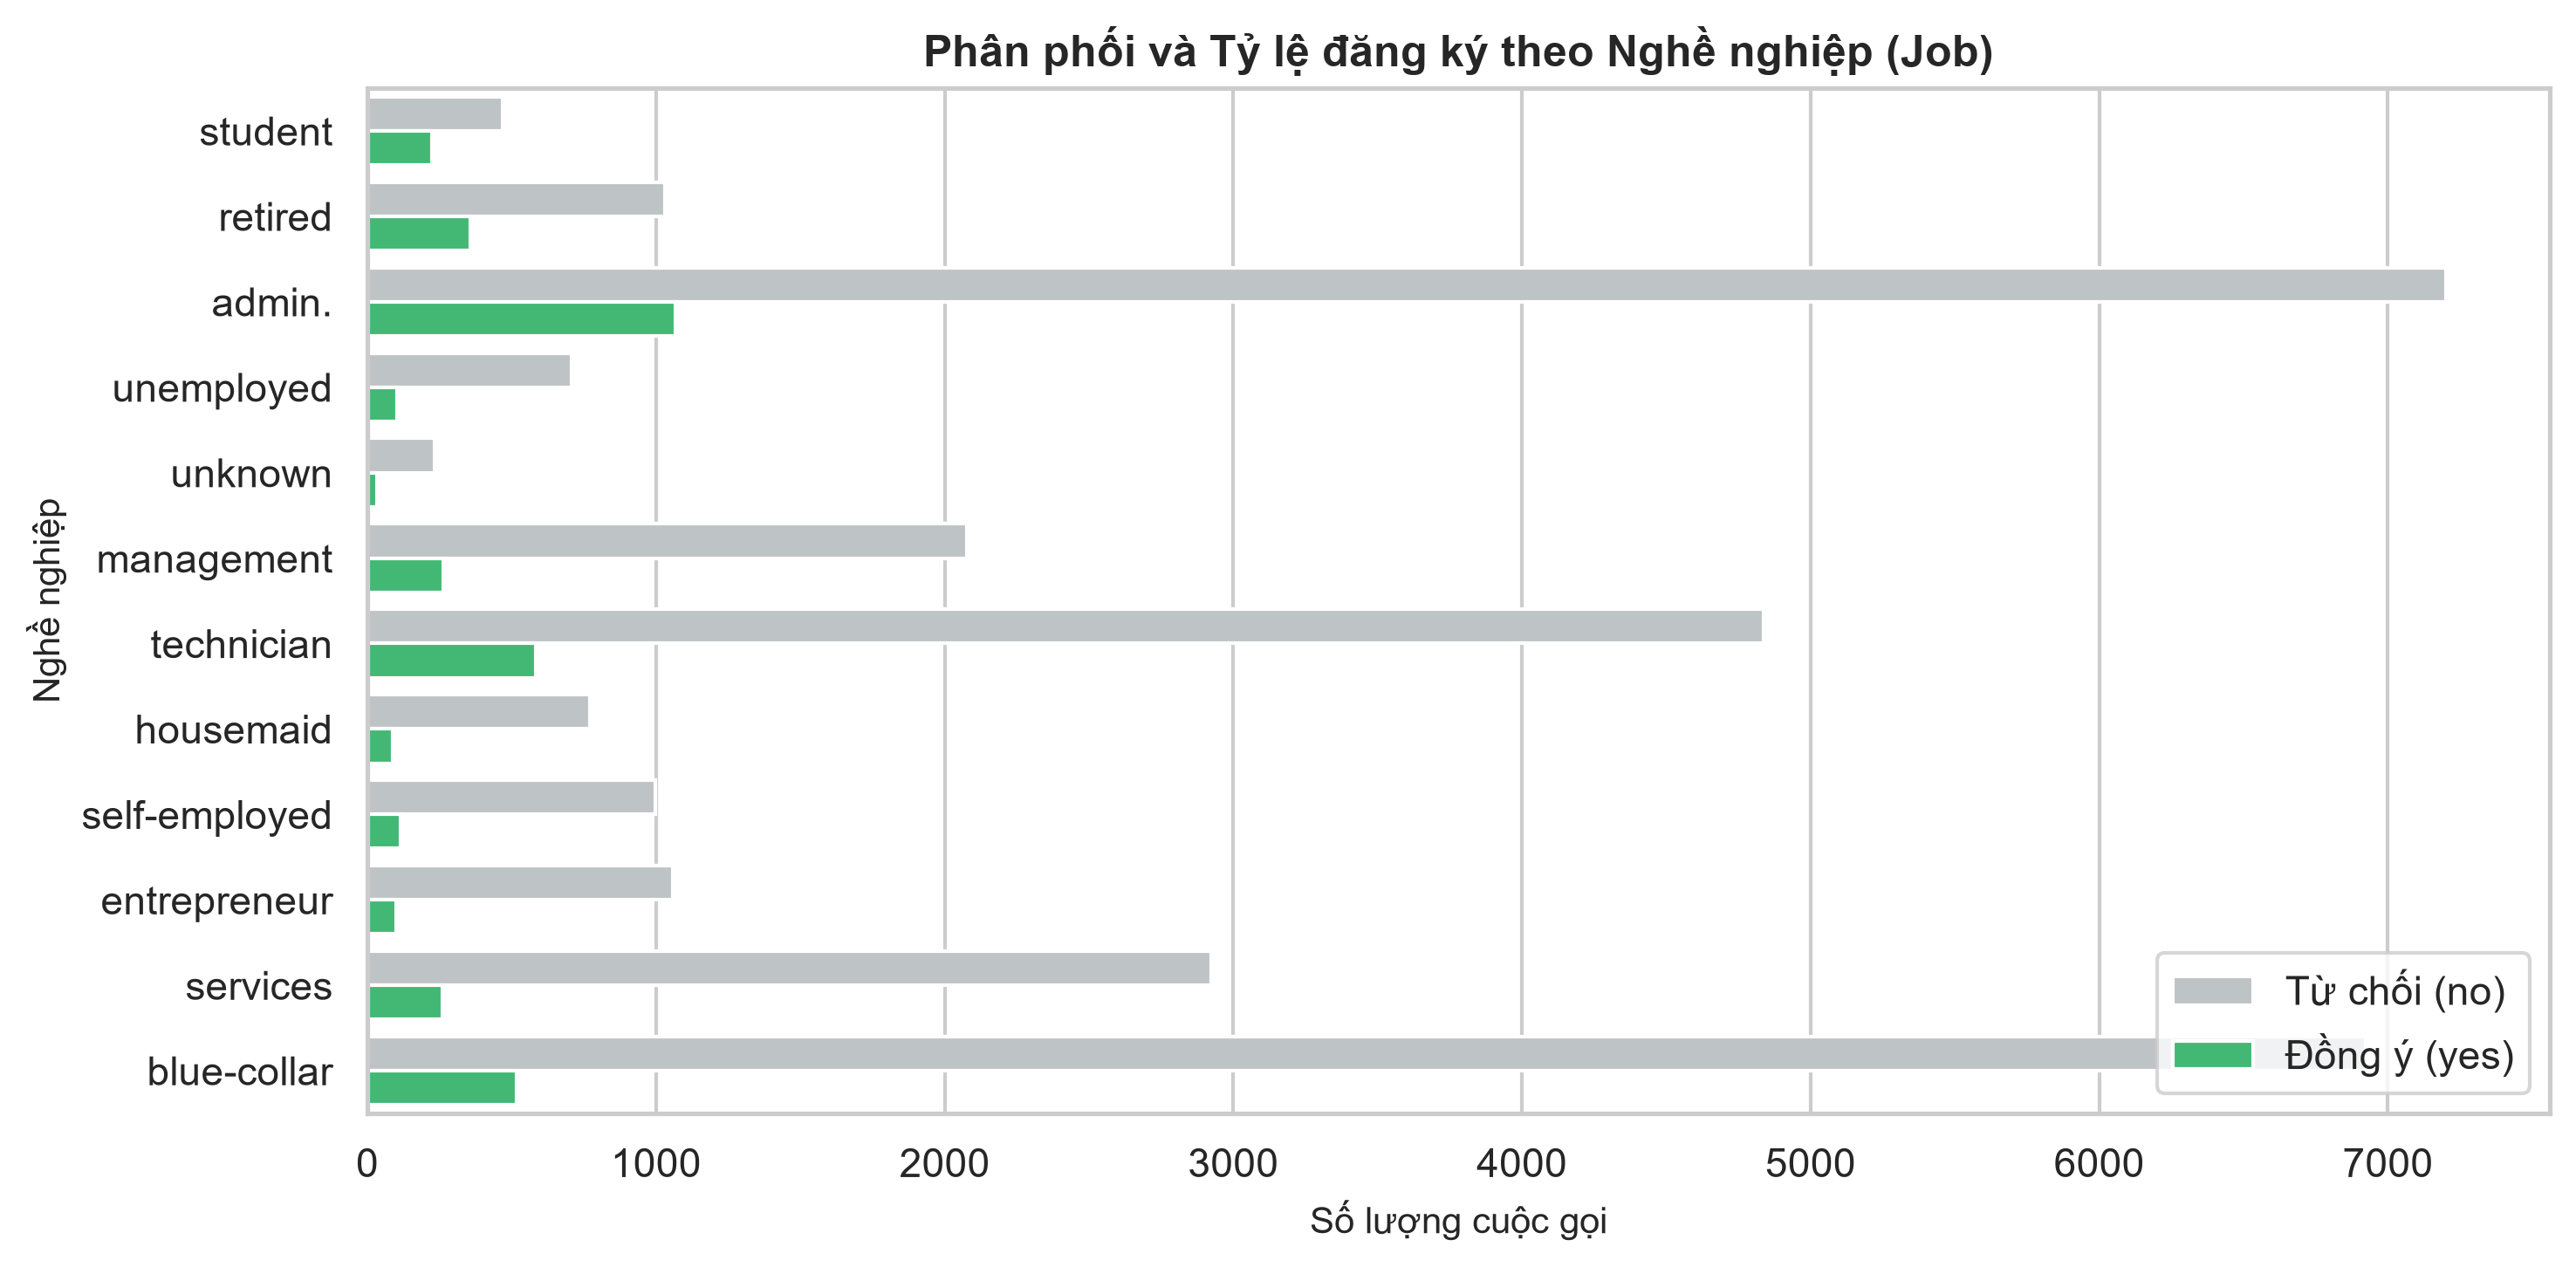

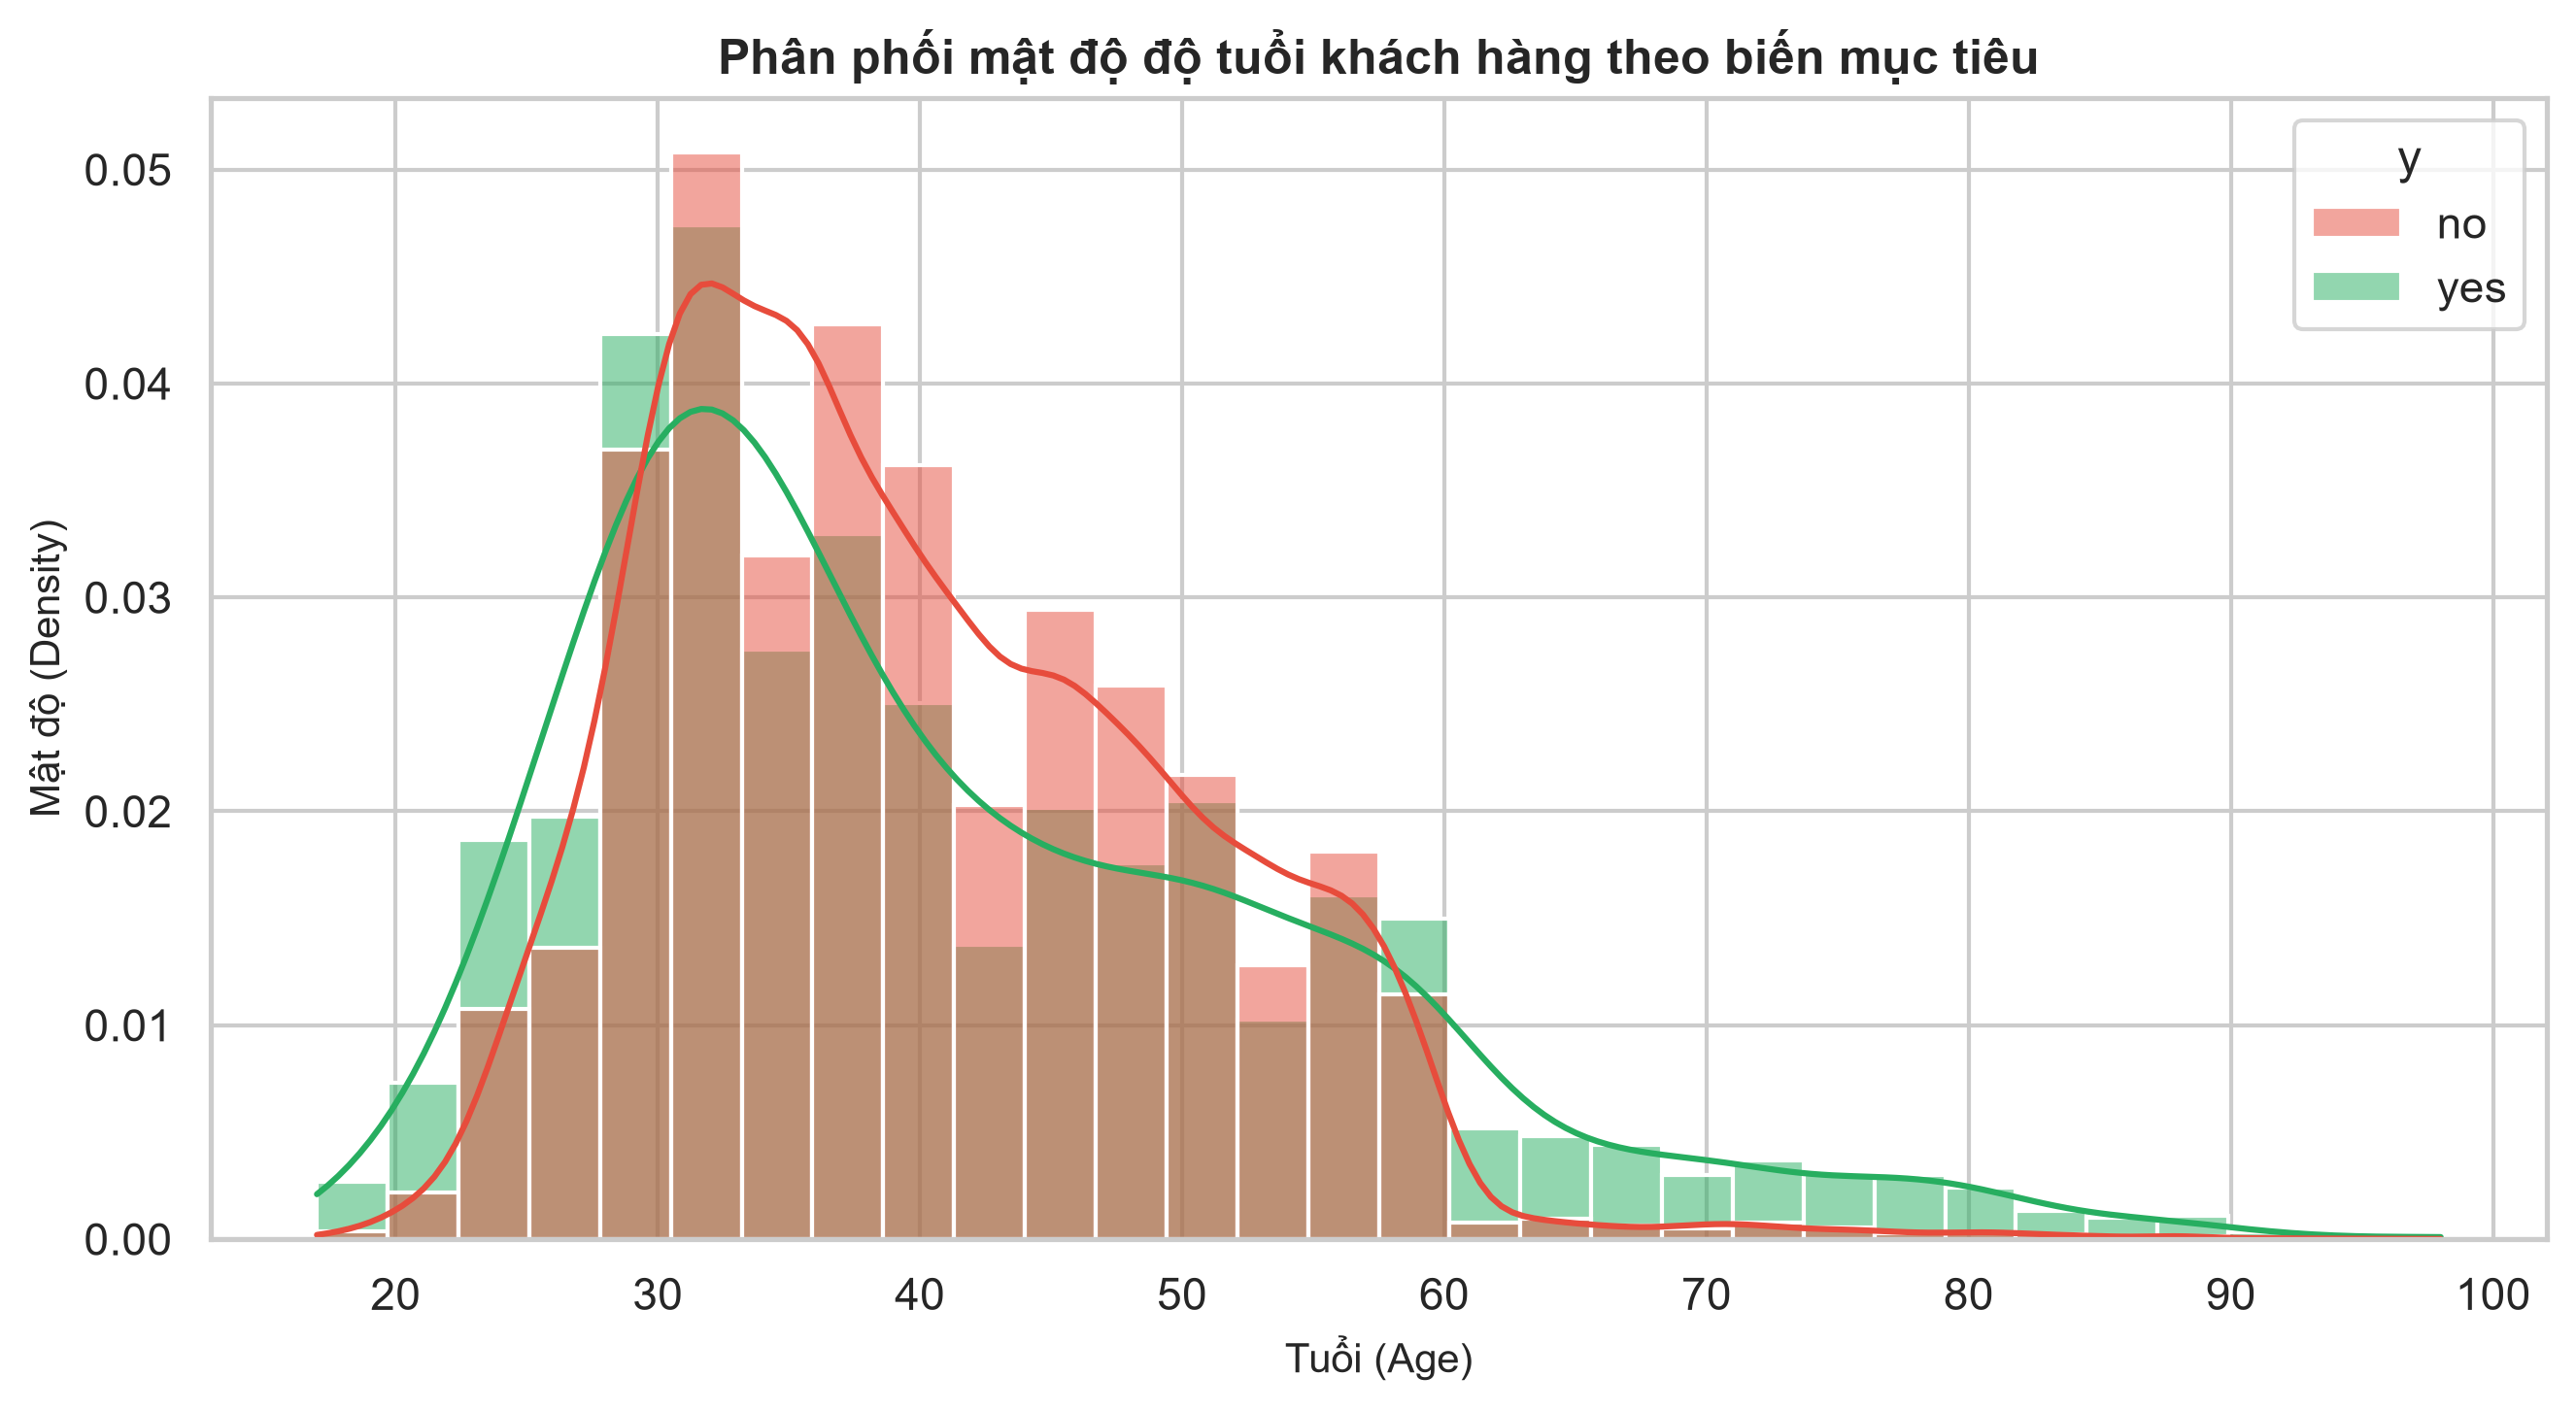

<Figure size 2400x1500 with 0 Axes>

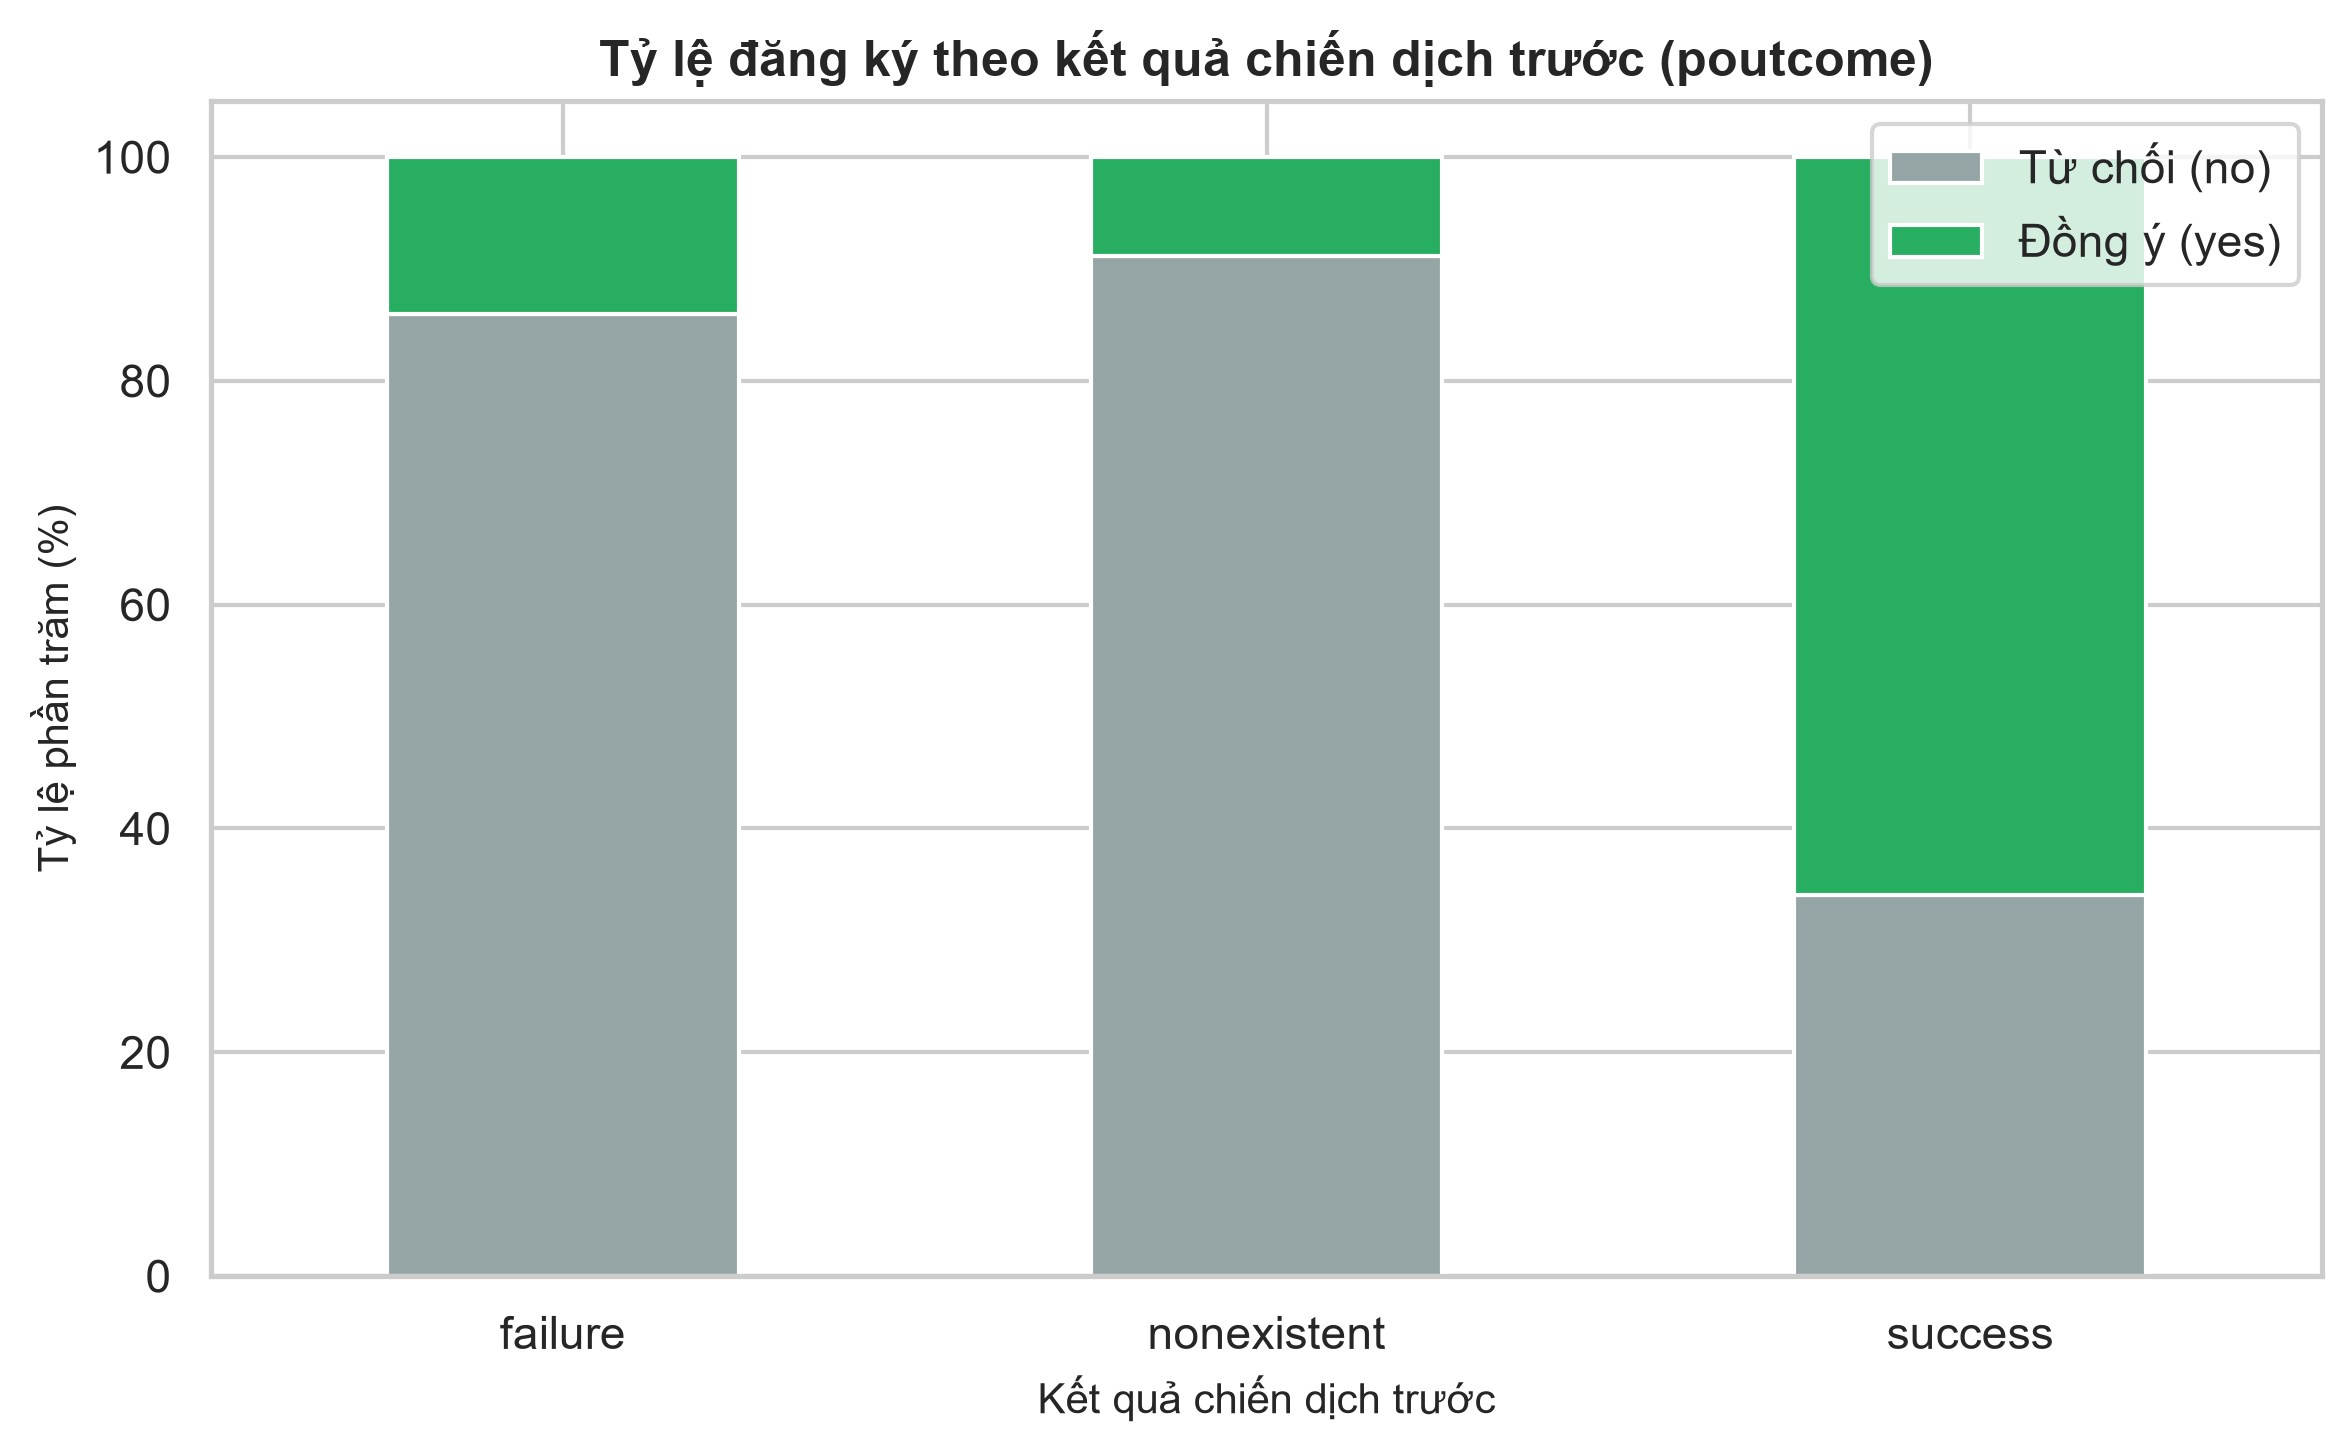

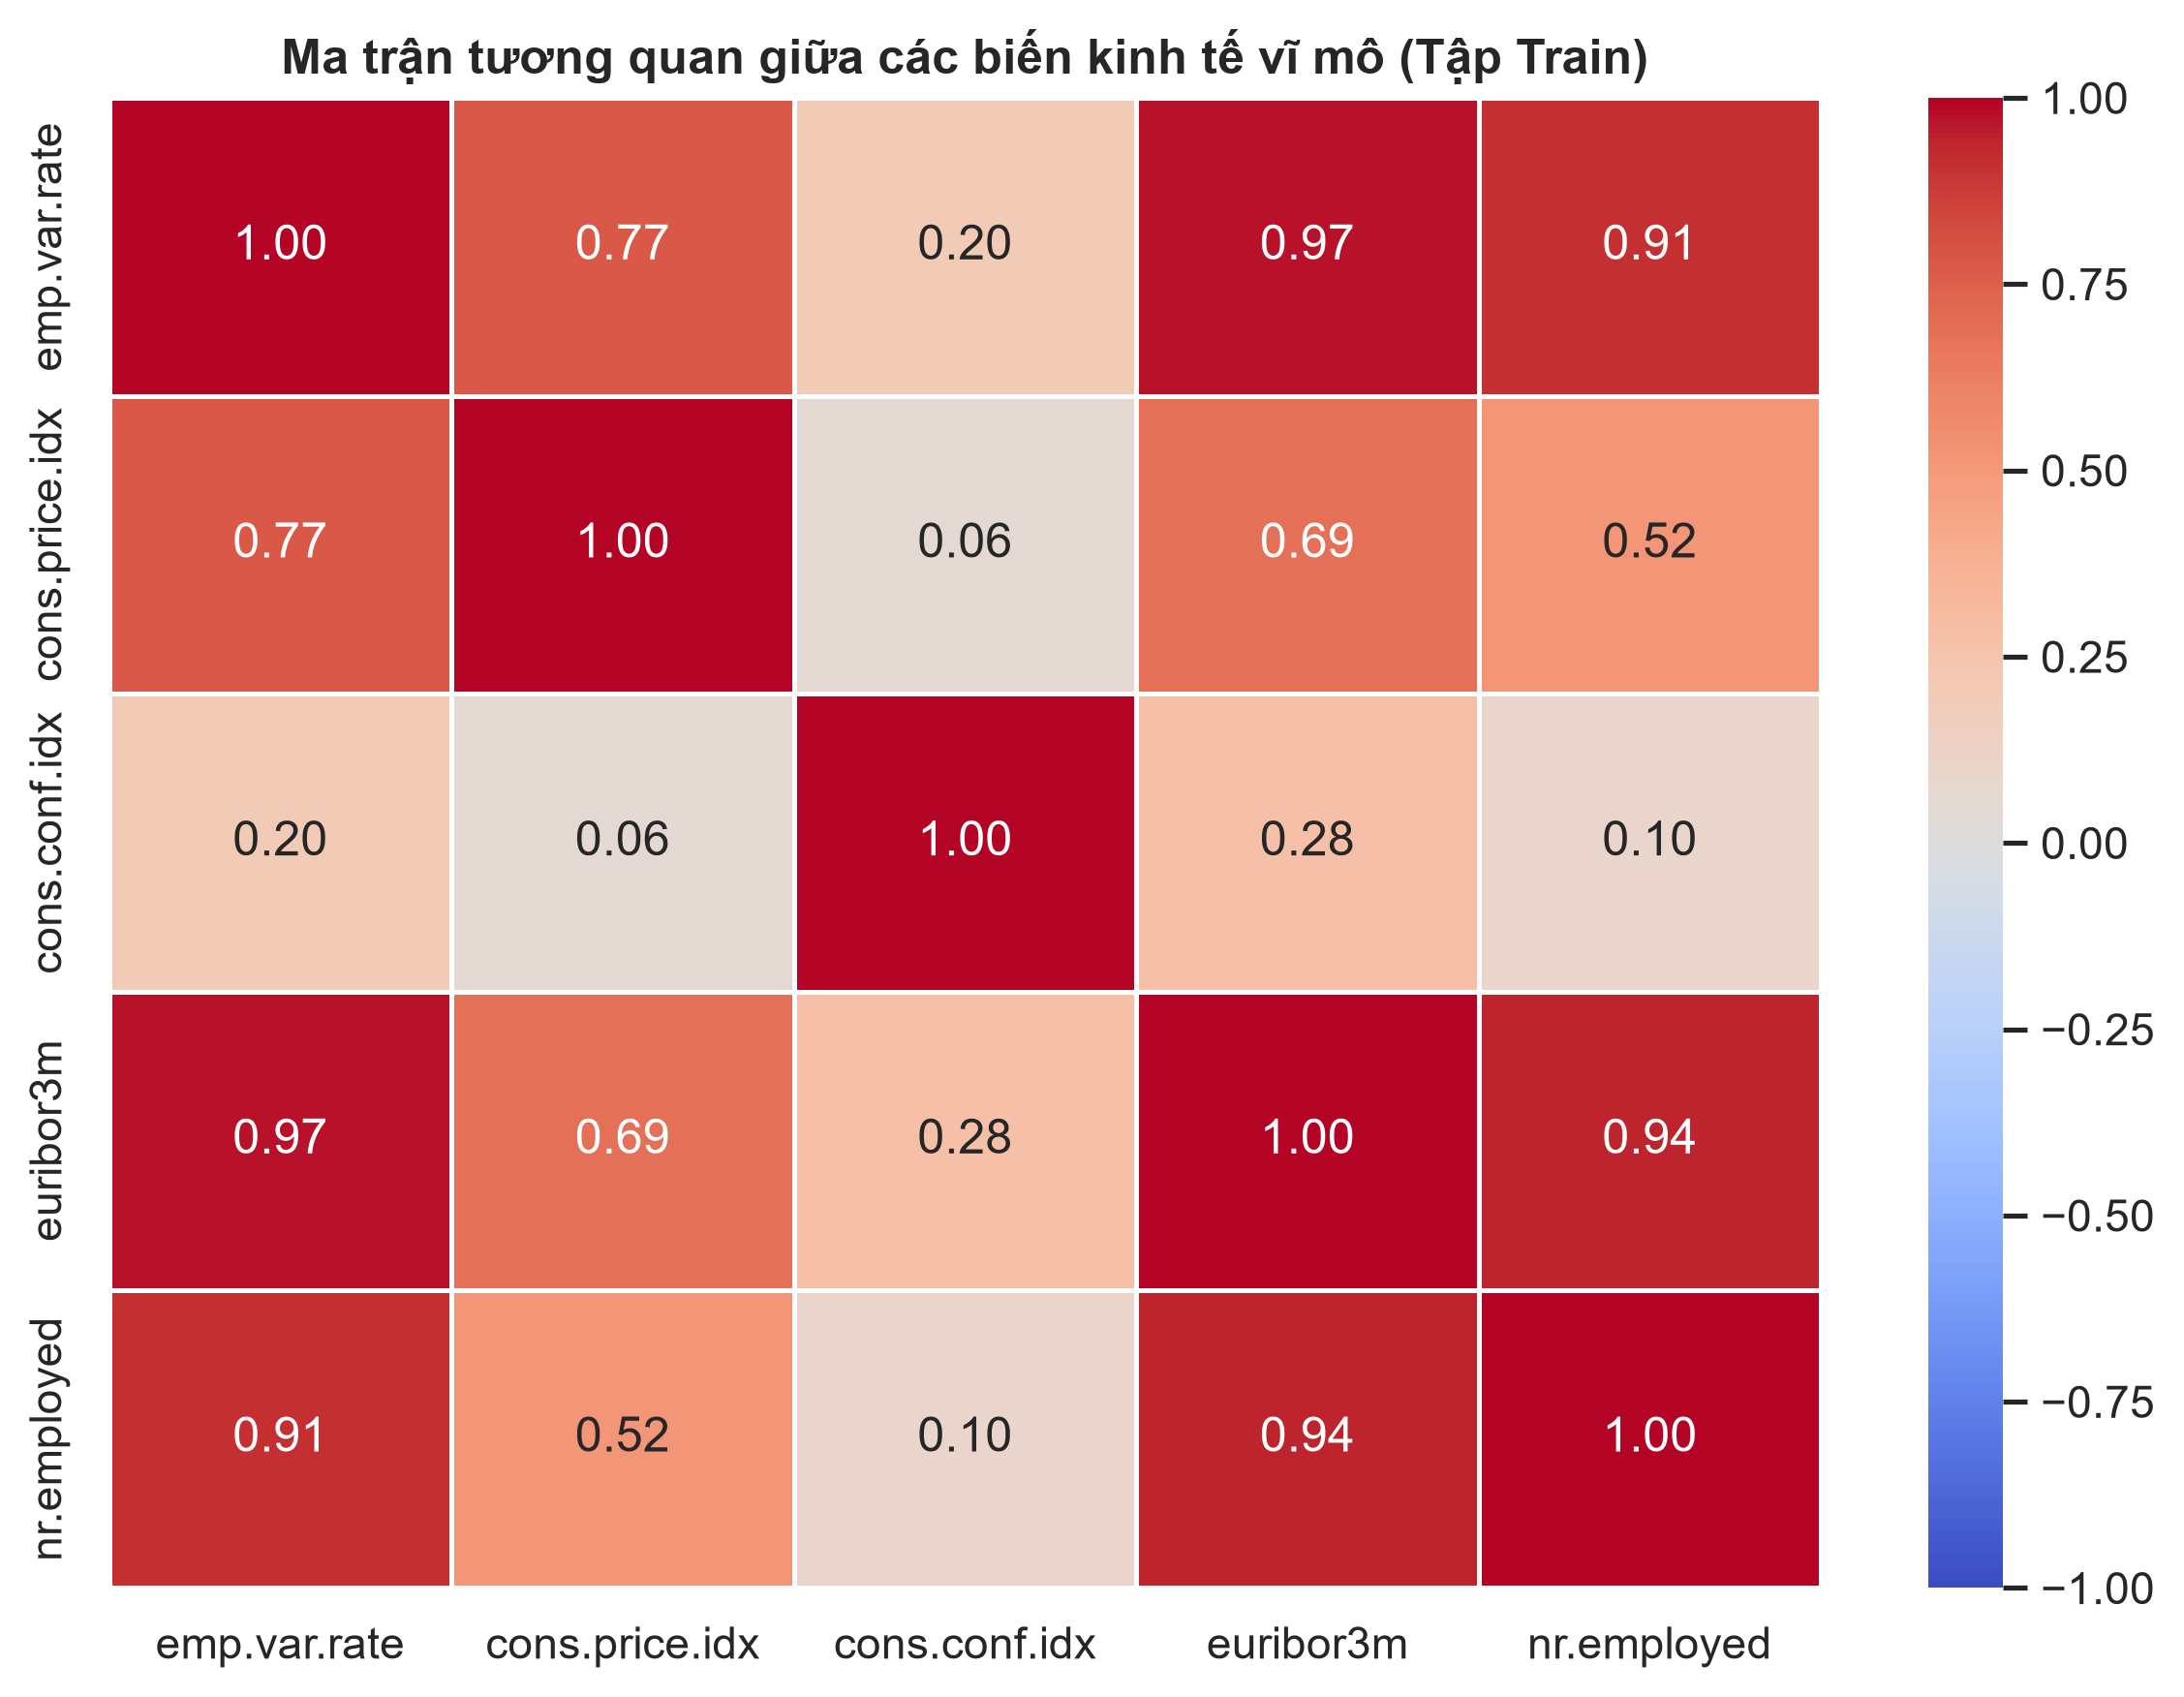


[*] ĐÃ XUẤT TOÀN BỘ 5 HÌNH GỐC NÉT CAO VÀO THƯ MỤC 'figures/' THÀNH CÔNG!


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách đồ thị học thuật chuẩn mực
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams['figure.dpi'] = 300
figures_dir = "../figures"
os.makedirs(figures_dir, exist_ok=True)

# BẢNG MÀU NHẤT QUÁN TOÀN BỘ ĐỒ ÁN:
# 'no'  -> Xanh xám trung tính (#4A6572)
# 'yes' -> Cam vàng nổi bật (#F39C12)
PALETTE = {'no': '#4A6572', 'yes': '#F39C12'}

# 1. ĐỌC DỮ LIỆU TẬP TRAIN (Chỉ EDA trên Train để tránh Data Snooping)
train_df = pd.read_csv("../Data/processed/train.csv", sep=";")
print(f"[*] Bắt đầu EDA trên tập Train: {train_df.shape[0]:,} mẫu.")

# ==============================================================================
# HÌNH 1: PHÂN PHỐI BIẾN MỤC TIÊU (SỬA LỖI SỐ NGUYÊN & MÀU CHUẨN)
# ==============================================================================
plt.figure(figsize=(6, 5))
ax = sns.countplot(x='y', data=train_df, palette=PALETTE)
plt.title("Hình 1: Phân phối biến mục tiêu (y) trên tập Train", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Khách hàng đăng ký gửi tiền?", fontsize=10)
plt.ylabel("Số lượng mẫu", fontsize=10)

total = len(train_df)
for p in ax.patches:
    height = int(p.get_height())  # ÉP SỐ NGUYÊN (Không còn .0)
    pct = 100 * height / total
    ax.annotate(f"{height:,}\n({pct:.2f}%)", (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{figures_dir}/01_train_target_distribution.png")
plt.show()

print("""
[NHẬN XÉT HÌNH 1]:
- Tỷ lệ mất cân bằng nghiêm trọng: 'no' chiếm 88.73% (29,229 mẫu), 'yes' chỉ chiếm 11.27% (3,711 mẫu).
[QUYẾT ĐỊNH KỸ THUẬT]:
- Không dùng Accuracy. Sử dụng ROC-AUC, PR-AUC, F1-Score (cho class 1).
- Áp dụng class_weight='balanced' hoặc tinh chỉnh threshold dự báo khi huấn luyện.
""")

# ==============================================================================
# HÌNH 2: TỶ LỆ ĐĂNG KÝ THỰC TẾ THEO NGHỀ NGHIỆP (VẼ TỶ LỆ % KÈM SỐ MẪU N)
# ==============================================================================
job_stats = train_df.groupby('job')['y'].agg(
    total='count',
    yes_count=lambda x: (x == 'yes').sum(),
    yes_rate=lambda x: (x == 'yes').mean() * 100
).sort_values(by='yes_rate', ascending=False).reset_index()

plt.figure(figsize=(10, 6))
bars = plt.barh(job_stats['job'], job_stats['yes_rate'], color='#F39C12', edgecolor='#D68910', alpha=0.85)
plt.gca().invert_yaxis()  # Nghề có tỷ lệ cao nhất nằm ở trên cùng
plt.title("Hình 2: Tỷ lệ đăng ký gửi tiền thực tế theo Nghề nghiệp (% Yes)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Tỷ lệ đăng ký (% Yes)", fontsize=10)
plt.ylabel("Nghề nghiệp", fontsize=10)

for bar, (_, row) in zip(bars, job_stats.iterrows()):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f"{row['yes_rate']:.1f}% (N={int(row['total']):,})",
             va='center', fontsize=9, fontweight='semibold', color='#2C3E50')

plt.xlim(0, max(job_stats['yes_rate']) + 8)
plt.tight_layout()
plt.savefig(f"{figures_dir}/02_train_job_conversion_rate.png")
plt.show()

print("""
[NHẬN XÉT HÌNH 2]:
- Nhóm sinh viên (student - 32.3%, N=697) và người nghỉ hưu (retired - 25.8%, N=1,366) có tỷ lệ đồng ý rất cao.
- Nhóm công nhân (blue-collar) chiếm số lượng áp đảo (N=7,404) nhưng tỷ lệ đồng ý chỉ đạt 6.9%.
[QUYẾT ĐỊNH KỸ THUẬT]:
- Nghề nghiệp là biến phân loại có giá trị dự báo mạnh. Áp dụng One-Hot Encoding hoặc Target Encoding.
""")

# ==============================================================================
# HÌNH 3: PHÂN TÍCH BIẾN LỆCH & NGOẠI LỆ (CAMPAIGN, PREVIOUS, DURATION)
# ==============================================================================
skew_cols = ['campaign', 'previous', 'duration']
skew_values = train_df[skew_cols].skew()

# Tính tỷ lệ ngoại lệ theo IQR
outlier_info = {}
for col in skew_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = ((train_df[col] < (q1 - 1.5 * iqr)) | (train_df[col] > (q3 + 1.5 * iqr))).sum()
    outlier_info[col] = (outliers / len(train_df)) * 100

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, col in enumerate(skew_cols):
    sns.boxplot(y=train_df[col], ax=axes[i], color='#4A6572')
    axes[i].set_title(f"{col}\nSkewness: {skew_values[col]:.2f} | Outlier: {outlier_info[col]:.1f}%", fontsize=10, fontweight='bold')
    axes[i].set_ylabel("Giá trị", fontsize=9)

plt.suptitle("Hình 3: Phân tích độ lệch và giá trị ngoại lệ (IQR Boxplot)", fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(f"{figures_dir}/03_skewed_and_outliers.png")
plt.show()

print(f"""
[NHẬN XÉT HÌNH 3]:
- 'campaign' lệch phải rất nặng (Skew = {skew_values['campaign']:.2f}).
- 'previous' lệch phải cực mạnh (Skew = {skew_values['previous']:.2f}), có {outlier_info['previous']:.1f}% ngoại lệ do đa số khách hàng chưa từng được liên hệ (previous=0).
- 'duration' lệch phải (Skew = {skew_values['duration']:.2f}).
[QUYẾT ĐỊNH KỸ THUẬT]:
- Với 'campaign': Áp dụng Clip tại phân vị 99% hoặc Log-transform (np.log1p) trước khi đưa vào mô hình tuyến tính.
- Với 'previous': Tạo biến cờ nhị phân 'previous_contacted = (previous > 0)'.
- Với 'duration': Xem xét loại bỏ hoàn toàn để tránh Target Leakage!
""")

# ==============================================================================
# HÌNH 4: TỶ LỆ YES THEO THÁNG (MONTH) VÀ HÌNH THỨC LIÊN LẠC (CONTACT)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Tháng
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_stats = train_df.groupby('month')['y'].agg(
    total='count',
    rate=lambda x: (x == 'yes').mean() * 100
).reindex(month_order).reset_index()

ax1_bar = ax1.bar(month_stats['month'], month_stats['rate'], color='#F39C12', alpha=0.85)
ax1.set_title("Tỷ lệ % Yes theo Tháng", fontsize=11, fontweight='bold')
ax1.set_ylabel("Tỷ lệ % Yes", fontsize=10)
for bar, (_, row) in zip(ax1_bar, month_stats.iterrows()):
    if not np.isnan(row['rate']):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f"{row['rate']:.1f}%\n(N={int(row['total']):,})", ha='center', fontsize=8)
ax1.set_ylim(0, 60)

# Kênh liên lạc
contact_stats = train_df.groupby('contact')['y'].agg(
    total='count',
    rate=lambda x: (x == 'yes').mean() * 100
).reset_index()

ax2_bar = ax2.bar(contact_stats['contact'], contact_stats['rate'], color=['#F39C12', '#4A6572'], alpha=0.85)
ax2.set_title("Tỷ lệ % Yes theo Kênh liên lạc (Contact)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Tỷ lệ % Yes", fontsize=10)
for bar, (_, row) in zip(ax2_bar, contact_stats.iterrows()):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f"{row['rate']:.1f}%\n(N={int(row['total']):,})", ha='center', fontsize=9, fontweight='semibold')
ax2.set_ylim(0, 20)

plt.suptitle("Hình 4: Tỷ lệ đăng ký theo Tháng và Phương thức liên lạc", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f"{figures_dir}/04_month_and_contact_impact.png")
plt.show()

print("""
[NHẬN XÉT HÌNH 4]:
- Nghịch lý tháng 5: Tháng 5 có số cuộc gọi lớn nhất (N=11,019) nhưng tỷ lệ thành công chỉ đạt 6.4%. Ngược lại, các tháng 3, 9, 10, 12 có tỷ lệ yes rất cao (44-50%) nhưng cỡ mẫu rất nhỏ (chỉ 145-581 mẫu).
- Kênh liên lạc: Gọi qua di động (cellular - 14.7%) có tỷ lệ thành công cao gấp gần 3 lần điện thoại bàn (telephone - 5.2%).
[QUYẾT ĐỊNH KỸ THUẬT]:
- Cần mã hóa One-Hot cho cả 'month' và 'contact'. Lưu ý hiện tượng overfitting với các tháng cỡ mẫu nhỏ.
""")

# ==============================================================================
# HÌNH 5: PHÂN TÍCH GIÁ TRỊ 'unknown' (ĐẶC BIỆT CỘT DEFAULT)
# ==============================================================================
unknown_counts = (train_df[cat_cols] == 'unknown').sum()
unknown_pct = (unknown_counts / len(train_df)) * 100
unknown_df = pd.DataFrame({'unknown_count': unknown_counts, 'percent': unknown_pct}).query('percent > 0').sort_values('percent', ascending=False)

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=unknown_df.index, y=unknown_df['percent'], color='#E74C3C', alpha=0.85)
plt.title("Hình 5: Tỷ lệ giá trị 'unknown' trên các cột phân loại (Tập Train)", fontsize=12, fontweight='bold', pad=12)
plt.ylabel("Tỷ lệ % unknown", fontsize=10)
plt.xlabel("Thuộc tính", fontsize=10)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}%", (p.get_x() + p.get_width() / 2., height + 0.5),
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.ylim(0, 25)
plt.tight_layout()
plt.savefig(f"{figures_dir}/05_unknown_values_distribution.png")
plt.show()

print("""
[NHẬN XÉT HÌNH 5]:
- Cột 'default' (nợ xấu tín dụng) có tới 20.82% giá trị mang nhãn 'unknown'. Đặc biệt, toàn bộ dữ liệu chỉ có đúng 3 mẫu 'yes' đã từng vướng nợ xấu.
[QUYẾT ĐỊNH KỸ THUẬT]:
- KHÔNG XÓA DÒNG (vì mất hơn 20% dữ liệu).
- GIỮ 'unknown' THÀNH MỘT CATEGORY RIÊNG BIỆT: Khách hàng từ chối trả lời về lịch sử nợ xấu chính là một tín hiệu hành vi đặc trưng quan trọng!
""")

# ==============================================================================
# HÌNH 6: PHÂN TÍCH BIẾN PDAYS (MÃ 999 VÀ KHÁCH HÀNG CŨ)
# ==============================================================================
train_df['pdays_contacted'] = train_df['pdays'].apply(lambda x: "Chưa liên hệ (999)" if x == 999 else "Đã liên hệ trước")
pdays_analysis = train_df.groupby('pdays_contacted')['y'].agg(
    total='count',
    rate=lambda x: (x == 'yes').mean() * 100
).reset_index()

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x='pdays_contacted', y='rate', data=pdays_analysis, palette=['#4A6572', '#F39C12'])
plt.title("Hình 6: Tỷ lệ % Yes giữa nhóm Khách hàng mới (999) và Khách hàng cũ", fontsize=11, fontweight='bold', pad=12)
plt.ylabel("Tỷ lệ đăng ký (% Yes)", fontsize=10)
plt.xlabel("Tình trạng liên hệ trước đây (pdays)", fontsize=10)

pdays_999_pct = (train_df['pdays'] == 999).mean() * 100
for p, (_, row) in zip(ax.patches, pdays_analysis.iterrows()):
    height = p.get_height()
    pct_total = (row['total'] / len(train_df)) * 100
    ax.annotate(f"{height:.1f}%\n(N={int(row['total']):,}, {pct_total:.1f}% tổng mẫu)",
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{figures_dir}/06_pdays_impact.png")
plt.show()

print(f"""
[NHẬN XÉT HÌNH 6]:
- Có tới {pdays_999_pct:.2f}% mẫu mang giá trị 999 (nghĩa là chưa từng được tiếp thị ở chiến dịch trước).
- Tỷ lệ đăng ký ở nhóm đã từng được liên hệ lên tới {pdays_analysis.loc[pdays_analysis['pdays_contacted']=='Đã liên hệ trước', 'rate'].values[0]:.1f}%, trong khi nhóm mang mã 999 chỉ đạt {pdays_analysis.loc[pdays_analysis['pdays_contacted']=='Chưa liên hệ (999)', 'rate'].values[0]:.1f}%.
[QUYẾT ĐỊNH KỸ THUẬT (FEATURE ENGINEERING)]:
- Biến đổi 'pdays' thành 2 thuộc tính:
  1. Biến nhị phân: 'pdays_contacted = (pdays != 999)'.
  2. Phân cụm thời gian cho các khách hàng cũ: [0-7 ngày, 8-15 ngày, >15 ngày].
""")

# ==============================================================================
# HÌNH 7: BẰNG CHỨNG RÒ RỈ DỮ LIỆU CỦA DURATION (TARGET LEAKAGE EVIDENCE)
# ==============================================================================
med_no = train_df[train_df['y']=='no']['duration'].median()
med_yes = train_df[train_df['y']=='yes']['duration'].median()

plt.figure(figsize=(9, 4.5))
sns.boxplot(x='y', y='duration', data=train_df, palette=PALETTE, showfliers=False)
plt.title(f"Hình 7: So sánh thời lượng cuộc gọi (duration) - Bằng chứng rò rỉ dữ liệu\n[Median: 'no'={med_no:.0f}s vs 'yes'={med_yes:.0f}s]", 
          fontsize=11, fontweight='bold', pad=12)
plt.xlabel("Kết quả đăng ký (y)", fontsize=10)
plt.ylabel("Thời lượng cuộc gọi (giây - không vẽ outliers)", fontsize=10)

plt.tight_layout()
plt.savefig(f"{figures_dir}/07_duration_leakage_evidence.png")
plt.show()

print(f"""
[NHẬN XÉT HÌNH 7]:
- Trung vị thời lượng cuộc gọi của nhóm 'yes' ({med_yes:.0f} giây) cao gấp gần 3 lần nhóm 'no' ({med_no:.0f} giây).
[QUYẾT ĐỊNH KỸ THUẬT SỐNG CÒN]:
- XÁC NHẬN TARGET LEAKAGE: Trong thực tế, telesale không thể biết trước cuộc gọi kéo dài bao lâu trước khi nhấc máy.
- BẮT BUỘC LOẠI BỎ 'duration' trong pipeline mô hình triển khai thực tế.
""")

# ==============================================================================
# HÌNH 8: MA TRẬN TƯƠNG QUAN KINH TẾ VĨ MÔ & ĐA CỘNG TUYẾN
# ==============================================================================
macro_cols = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
corr_matrix = train_df[macro_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', fmt=".2f", vmin=-1, vmax=1, linewidths=0.8)
plt.title("Hình 8: Ma trận tương quan giữa 5 biến kinh tế vĩ mô (Kiểm tra đa cộng tuyến)", fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(f"{figures_dir}/08_macro_correlation_heatmap.png")
plt.show()

print("""
[NHẬN XÉT HÌNH 8]:
- Tương quan cực mạnh giữa các biến vĩ mô:
  + emp.var.rate và euribor3m: r = 0.97
  + euribor3m và nr.employed: r = 0.94
  + emp.var.rate và nr.employed: r = 0.91
[QUYẾT ĐỊNH KỸ THUẬT]:
- Hiện tượng đa cộng tuyến (Multicollinearity) nghiêm trọng!
- Với mô hình tuyến tính (Logistic Regression): Bắt buộc kiểm tra VIF (Variance Inflation Factor) và loại bỏ bớt 2 trong 3 biến này hoặc dùng hồi quy Ridge/Lasso (L2/L1).
- Với mô hình dạng cây (Random Forest, XGBoost): Ít bị ảnh hưởng trực tiếp đến hiệu năng dự báo nhưng cần lưu ý khi diễn giải Feature Importance (SHAP values).
""")

print("\n[*] TOÀN BỘ 8 BIỂU ĐỒ VÀ NHẬN XÉT KỸ THUẬT ĐÃ ĐƯỢC XUẤT LƯU THÀNH CÔNG VÀO THƯ MỤC 'figures/'!")